# Benzene unbinding from T4 lysozyme L99A

46 reactive trajectories labelled by the egress routes reported in the literature (Nunes-Alves et al.), named after
the helices that line them. The paths differ strongly in length (34–814 frames), so they are compared with DTW
(Sakoe–Chiba band of 8 % of the longer path, widened to the length difference of each pair; distances divided
by √(n + m)); σ = median, α = 0.5.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]          # repository root (notebook lives in systems/<name>/)
sys.path[:0] = [str(ROOT), str(Path.cwd())]
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathfdm import embed
from pathfdm.features import feature_matrix
from pathfdm.surrogate import fit_surrogate
from pathfdm.evaluation import auc_per_coordinate, kmeans_ari, align_signs, compare_embeddings
from pathfdm.plotting import apply_style, plot_space, plot_parity, plot_beeswarm
import load_data as D
apply_style()
N_JOBS = 8
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

In [2]:
ts, labels = D.load(n_jobs=N_JOBS)
{D.LABEL_CONFIG[k]['name']: int((labels == k).sum()) for k in D.LABEL_CONFIG}

/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"


/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"


/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"


/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/Soft/miniconda3/envs/cvs/lib/python3.11/site-packages/MDAnalysis/coordinates/DCD.py:171: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn("DCDReader currently makes independent timesteps"
/home/shaheerah/

46 trajectories | 12 solute atoms + 0 water oxygens | 34-814 frames | 36 coordinates per frame


{'DG': 13, 'FGH': 19, 'HJ': 9, 'EJ': 1, 'CD': 1, 'FI': 3}

## FDM embedding (DTW)

sigma = 17.028 | k-means (k = 6) on FDM 0-2: ARI = 0.90


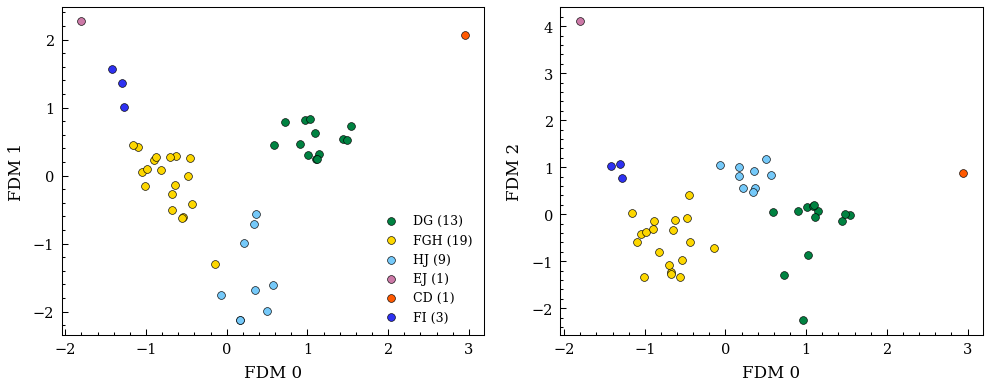

In [3]:
Z, model = embed(ts.fd, metric="dtw", window="sakoe_chiba_wide", alpha=0.5, normalize_length=True,
                 return_model=True, n_jobs=N_JOBS)
ari = adjusted_rand_score(labels, KMeans(6, n_init=20, random_state=0).fit_predict(Z[:, :3]))
print(f"sigma = {model.sigma_:.3f} | k-means (k = 6) on FDM 0-2: ARI = {ari:.2f}")
fig, axs = plt.subplots(1, 2, figsize=(6.8, 2.8))
plot_space(Z, labels, D.LABEL_CONFIG, ax=axs[0]); plot_space(Z, labels, D.LABEL_CONFIG, dims=(0, 2), ax=axs[1], legend=False)
plt.tight_layout(); plt.show()

## Does FDM sort the paths by length?

DTW aligns paths of different length, so FDM could in principle order them by duration alone.

Spearman rho(FDM 0, length) = 0.55
median length per route: {'DG': 395, 'FGH': 104, 'HJ': 153, 'EJ': 99, 'CD': 90, 'FI': 94}
k-means on log(length) alone: ARI = 0.04


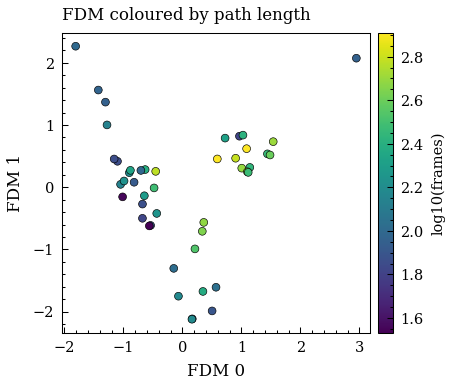

In [4]:
L = ts.lengths
print(f"Spearman rho(FDM 0, length) = {spearmanr(Z[:, 0], L).statistic:.2f}")
print("median length per route:", {D.LABEL_CONFIG[k]['name']: int(np.median(L[labels == k])) for k in D.LABEL_CONFIG})
ari_len = adjusted_rand_score(labels, KMeans(6, n_init=20, random_state=0).fit_predict(np.log(L)[:, None]))
print(f"k-means on log(length) alone: ARI = {ari_len:.2f}")
plot_space(Z, c=np.log10(L), clabel="log10(frames)", title="FDM coloured by path length"); plt.show()

## Setting: kernel bandwidth σ and α

In [5]:
from pathfdm import FDM
from sklearn.preprocessing import StandardScaler
rows = []
for f in (0.5, 0.75, 1.0, 1.5, 2.0):
    for a in (0.0, 0.5, 1.0):          # the DTW distances are computed once and reused
        m = FDM(n_components=10, sigma=f * model.sigma_, alpha=a)
        Zs = StandardScaler().fit_transform(m.fit_transform(None, precomputed_D=model.D_matrix))
        rows.append({"sigma / median": f, "alpha": a,
                     "ARI": adjusted_rand_score(labels, KMeans(6, n_init=20, random_state=0).fit_predict(Zs[:, :3]))})
pd.DataFrame(rows).pivot(index="sigma / median", columns="alpha", values="ARI").round(2)

alpha,0.0,0.5,1.0
sigma / median,,,
0.50,0.87,0.87,0.93
0.75,1.00,1.00,1.00
1.00,0.90,0.90,0.80
1.50,0.66,0.68,0.66
2.00,0.68,0.70,0.68
